# FedEduAI — Experiment 1-A (UCI), run v25

Complete run of Experiment 1-A on the UCI Student Performance dataset (1,044 records) with the protocol described in Section 4.2.1 of the paper. The notebook reports the mean ± standard deviation of accuracy, macro-F1 and ROC-AUC over five seeds.

Execution: Runtime ▸ Run all. No GPU is required (about 3–5 minutes on CPU). The data are downloaded automatically from the UCI repository.

Outputs: `exp1a_uci_v25.zip` (also saved to Google Drive) containing the raw per-seed results and the summary table.


In [1]:
# (optional) save a copy of the results to Google Drive
SAVE_TO_DRIVE = True
OUT_DRIVE = '/content/drive/MyDrive/iudb/results/exp1a_v25'
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive; drive.mount('/content/drive')
    except Exception as e:
        print('Drive not mounted:', e); SAVE_TO_DRIVE = False

Drive not mounted: mount failed


In [2]:
!pip -q install xgboost
import xgboost, sklearn, torch; print('xgboost', xgboost.__version__, '| sklearn', sklearn.__version__, '| torch', torch.__version__)

xgboost 3.4.1 | sklearn 1.6.1 | torch 2.11.0+cpu


In [3]:
# ---- FedEduAI Experiment 1-A (v25): UCI Student Performance, full re-run with mean ± SD for every metric ----
import os, io, json, time, zipfile, hashlib, urllib.request, platform
import numpy as np, pandas as pd
import torch, torch.nn as nn
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None

VERSION = 'v25'; SEEDS = [0, 1, 2, 3, 4]
FED_ROUNDS, LOCAL_EPOCHS = 25, 4                     # as in the paper: 25 rounds, 4 local epochs
CENTRAL_EPOCHS = FED_ROUNDS * LOCAL_EPOCHS           # same number of passes over the data
URL = 'https://archive.ics.uci.edu/static/public/320/student+performance.zip'

def load_uci(cache='uci_student.zip'):
    if not os.path.exists(cache):
        urllib.request.urlretrieve(URL, cache)
    sha = hashlib.sha256(open(cache, 'rb').read()).hexdigest()
    outer = zipfile.ZipFile(cache); inner = zipfile.ZipFile(io.BytesIO(outer.read('student.zip')))
    frames = []
    for subj, fn in (('mat', 'student-mat.csv'), ('por', 'student-por.csv')):
        df = pd.read_csv(io.BytesIO(inner.read(fn)), sep=';'); df['subject'] = subj; frames.append(df)
    df = pd.concat(frames, ignore_index=True)
    assert len(df) == 1044, len(df)
    return df, sha

def prepare(df):
    y = (df['G3'] >= 10).astype(int).values                         # binary pass target, G3 >= 10
    client = (df['school'] + '_' + df['subject']).values               # natural non-IID partition: school x subject (4 clients)
    X = df.drop(columns=['G3', 'subject'])                             # the 32 original attributes (G1 and G2 included)
    X = pd.get_dummies(X, drop_first=False).astype(float)
    seq = df[['G1', 'G2']].values.astype(np.float32) / 20.0            # grade sequence for the LSTM
    return X.values.astype(np.float32), y, client, seq, list(X.columns)

def metrics(y, p):
    pred = (p >= 0.5).astype(int)
    return {'acc': float(accuracy_score(y, pred)), 'macro_f1': float(f1_score(y, pred, average='macro')), 'auc': float(roc_auc_score(y, p))}

class MLP(nn.Module):
    def __init__(self, d):
        super().__init__(); self.net = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 2))
    def forward(self, x): return self.net(x)

class SeqLSTM(nn.Module):
    def __init__(self, h=16):
        super().__init__(); self.lstm = nn.LSTM(1, h, batch_first=True); self.fc = nn.Linear(h, 2)
    def forward(self, x):
        o, _ = self.lstm(x.unsqueeze(-1)); return self.fc(o[:, -1])

def train_epochs(model, X, y, epochs, seed, lr=1e-3, bs=32):
    g = torch.Generator().manual_seed(seed); opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4); lossf = nn.CrossEntropyLoss()
    X = torch.from_numpy(X); y = torch.from_numpy(y).long()
    for _ in range(epochs):
        model.train(); perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), bs):
            ix = perm[i:i + bs]; opt.zero_grad(); lossf(model(X[ix]), y[ix]).backward(); opt.step()
    return model

@torch.no_grad()
def proba(model, X):
    model.eval(); return torch.softmax(model(torch.from_numpy(X)), 1)[:, 1].numpy()

def fedavg(Xtr, ytr, ctr, d, seed):
    torch.manual_seed(seed); glob = MLP(d); clients = sorted(set(ctr))
    for r in range(FED_ROUNDS):
        states, sizes = [], []
        for k, c in enumerate(clients):
            m = ctr == c
            if m.sum() == 0: continue
            loc = MLP(d); loc.load_state_dict(glob.state_dict())
            train_epochs(loc, Xtr[m], ytr[m], LOCAL_EPOCHS, seed * 1000 + r * 10 + k)
            states.append(loc.state_dict()); sizes.append(int(m.sum()))
        w = np.array(sizes, float) / sum(sizes)
        glob.load_state_dict({key: sum(wi * s[key] for wi, s in zip(w, states)) for key in states[0]})
    return glob

def run(seeds=SEEDS, log=print):
    df, sha = load_uci(); X, y, client, seq, cols = prepare(df)
    log(f'UCI Student Performance: n={len(y)}, features={X.shape[1]} after one-hot, pass rate={y.mean():.3f}, clients={ {k: int(v) for k, v in pd.Series(client).value_counts().items()} }, sha256={sha[:16]}')
    res = {'version': VERSION, 'dataset_sha256': sha, 'n': int(len(y)), 'pass_rate': float(y.mean()), 'seeds': seeds,
           'protocol': 'Binary pass target (G3 >= 10); 32 original attributes incl. G1, G2 (one-hot encoded); five stratified 80/20 splits (seeds 0-4); '
                       'scaler fitted on the training part only; FedAvg over 4 clients (school x subject) for 25 rounds x 4 local epochs, '
                       'centralised deep model trained for the same 100 epochs; threshold 0.5; DP and SecAgg not applied.',
           'environment': {'python': platform.python_version(), 'torch': torch.__version__, 'xgboost_available': XGBClassifier is not None}, 'runs': []}
    for seed in seeds:
        t0 = time.time(); torch.manual_seed(seed); np.random.seed(seed)
        tr, te = next(StratifiedShuffleSplit(1, test_size=0.2, random_state=seed).split(X, y))
        sc = StandardScaler().fit(X[tr]); Xs = sc.transform(X).astype(np.float32); out = {}
        out['random_forest'] = metrics(y[te], RandomForestClassifier(n_estimators=500, random_state=seed, n_jobs=-1).fit(Xs[tr], y[tr]).predict_proba(Xs[te])[:, 1])
        if XGBClassifier is not None:
            xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9, eval_metric='logloss', random_state=seed, n_jobs=-1)
            out['xgboost'] = metrics(y[te], xgb.fit(Xs[tr], y[tr]).predict_proba(Xs[te])[:, 1])
        ann = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=seed)
        out['ann'] = metrics(y[te], ann.fit(Xs[tr], y[tr]).predict_proba(Xs[te])[:, 1])
        torch.manual_seed(seed); lstm = train_epochs(SeqLSTM(), seq[tr], y[tr], 100, seed, lr=5e-3)
        out['lstm_grade_sequence'] = metrics(y[te], proba(lstm, seq[te]))
        torch.manual_seed(seed); cen = train_epochs(MLP(X.shape[1]), Xs[tr], y[tr], CENTRAL_EPOCHS, seed)
        out['deep_centralised'] = metrics(y[te], proba(cen, Xs[te]))
        fed = fedavg(Xs[tr], y[tr], client[tr], X.shape[1], seed)
        out['deep_federated'] = metrics(y[te], proba(fed, Xs[te]))
        res['runs'].append({'seed': seed, 'n_train': int(len(tr)), 'n_test': int(len(te)), 'test_clients': {k: int(v) for k, v in pd.Series(client[te]).value_counts().items()}, 'results': out, 'seconds': round(time.time() - t0, 1)})
        log(f'seed {seed}: ' + '  '.join(f'{m}={v["acc"]:.3f}/{v["macro_f1"]:.3f}/{v["auc"]:.3f}' for m, v in out.items()))
    summ = {}
    for m in res['runs'][0]['results']:
        summ[m] = {}
        for k in ('acc', 'macro_f1', 'auc'):
            v = np.array([r['results'][m][k] for r in res['runs']]); summ[m][k] = {'mean': float(v.mean()), 'sd': float(v.std(ddof=1)) if len(v) > 1 else None}
    res['summary'] = summ
    d = np.array([r['results']['deep_federated']['acc'] - r['results']['deep_centralised']['acc'] for r in res['runs']])
    res['federated_minus_centralised_acc'] = {'mean': float(d.mean()), 'sd': float(d.std(ddof=1)) if len(d) > 1 else None, 'per_seed': d.round(4).tolist()}
    return res

NAMES = {'random_forest': 'Random forest', 'xgboost': 'XGBoost', 'ann': 'Artificial neural network (ANN)', 'lstm_grade_sequence': 'LSTM (grade sequence)',
         'deep_centralised': 'Deep learning - centralised', 'deep_federated': 'Deep learning - federated (proposed)'}
def table_md(res):
    lines = ['| Model | Accuracy (%) | Macro-F1 (%) | ROC-AUC |', '|---|---|---|---|']
    for m, s in res['summary'].items():
        sd = lambda k, f: f"{f * (s[k]['sd'] or 0):.{1 if f == 100 else 3}f}"
        lines.append(f"| {NAMES[m]} | {100*s['acc']['mean']:.1f} ± {sd('acc', 100)} | {100*s['macro_f1']['mean']:.1f} ± {sd('macro_f1', 100)} | {s['auc']['mean']:.3f} ± {sd('auc', 1)} |")
    return '\n'.join(lines)


In [4]:
import json, os, shutil, time
t0 = time.time(); res = run()
res['runtime_seconds'] = round(time.time() - t0, 1)
os.makedirs('exp1a_v25', exist_ok=True)
json.dump(res, open('exp1a_v25/exp1a_uci_v25.json', 'w'), indent=1, default=str)
md = table_md(res); open('exp1a_v25/table3_v25.md', 'w').write(md)
print(md); print('\nFederated - centralised accuracy:', res['federated_minus_centralised_acc'])
assert res['environment']['xgboost_available'], 'xgboost missing - the XGBoost row would be absent'

UCI Student Performance: n=1044, features=58 after one-hot, pass rate=0.780, clients={'GP_por': 423, 'GP_mat': 349, 'MS_por': 226, 'MS_mat': 46}, sha256=82ae9d66437b9808
seed 0: random_forest=0.919/0.879/0.968  xgboost=0.919/0.884/0.969  ann=0.866/0.775/0.922  lstm_grade_sequence=0.919/0.886/0.978  deep_centralised=0.914/0.873/0.975  deep_federated=0.909/0.857/0.973
seed 1: random_forest=0.928/0.887/0.982  xgboost=0.928/0.889/0.977  ann=0.880/0.801/0.919  lstm_grade_sequence=0.943/0.919/0.984  deep_centralised=0.914/0.855/0.954  deep_federated=0.890/0.805/0.940
seed 2: random_forest=0.938/0.909/0.978  xgboost=0.928/0.895/0.977  ann=0.895/0.836/0.945  lstm_grade_sequence=0.914/0.880/0.981  deep_centralised=0.919/0.879/0.968  deep_federated=0.919/0.874/0.966
seed 3: random_forest=0.909/0.855/0.956  xgboost=0.914/0.863/0.938  ann=0.809/0.588/0.831  lstm_grade_sequence=0.914/0.858/0.967  deep_centralised=0.876/0.806/0.916  deep_federated=0.885/0.814/0.925
seed 4: random_forest=0.909/0.852/

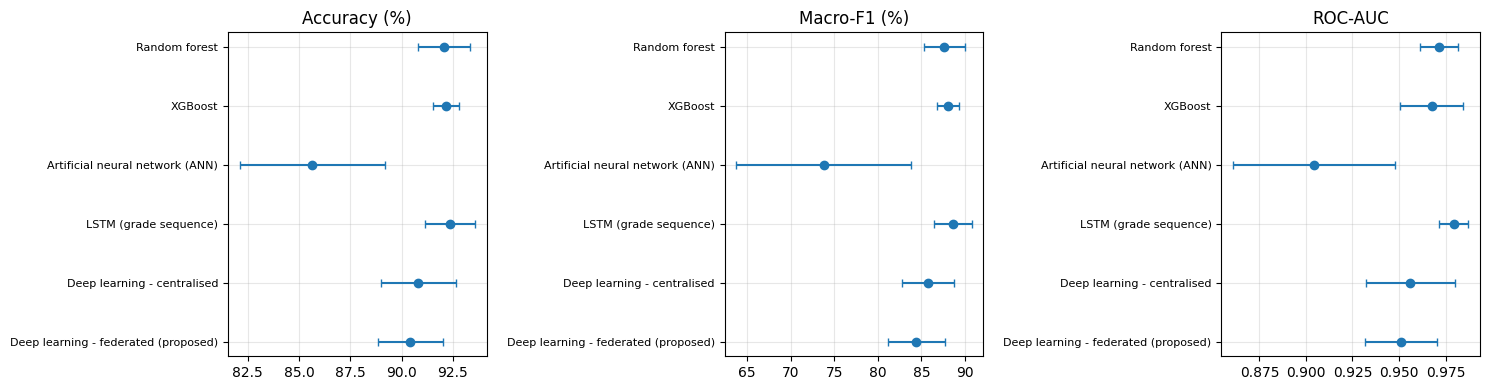

In [5]:
import matplotlib.pyplot as plt, numpy as np
order = [m for m in NAMES if m in res['summary']]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, k, lab in zip(ax, ('acc', 'macro_f1', 'auc'), ('Accuracy (%)', 'Macro-F1 (%)', 'ROC-AUC')):
    f = 1 if k == 'auc' else 100
    m = [f * res['summary'][o][k]['mean'] for o in order]; s = [f * res['summary'][o][k]['sd'] for o in order]
    a.errorbar(m, range(len(order)), xerr=s, fmt='o', capsize=3); a.set_yticks(range(len(order))); a.set_yticklabels([NAMES[o] for o in order], fontsize=8)
    a.invert_yaxis(); a.set_title(lab); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig('exp1a_v25/preview_v25.png', dpi=150); plt.show()

In [6]:
shutil.make_archive('exp1a_uci_v25', 'zip', 'exp1a_v25')
if SAVE_TO_DRIVE:
    os.makedirs(OUT_DRIVE, exist_ok=True); shutil.copy('exp1a_uci_v25.zip', OUT_DRIVE); print('saved to', OUT_DRIVE)
try:
    from google.colab import files; files.download('exp1a_uci_v25.zip')
except Exception as e:
    print('download manually: exp1a_uci_v25.zip', e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>